<h1 style="color: #123854; font-size: 29px; border-bottom: 3px solid #3b82c4; padding-bottom: 10px; margin-bottom: 20px;">Exploratory Data Analysis</h1>

In [2]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import pearsonr, spearmanr, linregress, kruskal, mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 40)


DATA_PATH =  Path("marseille_cleaning_outputs/marseille_analysis_ready.csv")
if DATA_PATH is None:
    raise FileNotFoundError(
        "file not found"
    )

df = pd.read_csv(DATA_PATH, dtype={"zipcode": "string"}, low_memory=False)
required = [
    "source_site", "surface_m2", "price_total_eur", "price_per_m2",
    "property_type_label", "urban_zone", "arrondissement",
    "dpe_class", "dpe_numeric", "is_furnished_binary", "has_elevator_binary",
    "has_balcony_terrace_binary", "has_parking_binary", "is_renovated",
    "amenity_score", "amenities_known_count", "charges_eur",
    "charges_share_pct", "charges_eur_estimated", "depot_garantie_eur",
    "honoraires_eur", "upfront_move_in_cost_eur"
]
missing_columns = sorted(set(required) - set(df.columns))
if missing_columns:
    raise ValueError(f"Columns missing from the PREPROCESSED CSV: {missing_columns}")

binary_features = ["is_furnished_binary", "has_elevator_binary",
                   "has_balcony_terrace_binary", "has_parking_binary", "is_renovated"]
for col in binary_features:
    if not df[col].dropna().isin([0, 1]).all():
        raise ValueError(f"Unexpected coding in {col}; check the preprocessing output.")
if not df["dpe_class"].dropna().isin(list("ABCDEFG")).all():
    raise ValueError("Unexpected DPE class; check the preprocessing output.")
if not pd.api.types.is_bool_dtype(df["charges_eur_estimated"]):
    raise ValueError("charges_eur_estimated must be the boolean flag from preprocessing.")

# Analysis sample only: retain positive, non-missing surface and monthly rent.
eda = df.loc[df["surface_m2"].gt(0) & df["price_total_eur"].gt(0)].copy()
print(f"Loaded {len(df)} rows, {len(df.columns)} columns from {DATA_PATH}")
print(f"Positive surface and rent: {len(eda)} advertisements")
print(f"Estimated charges: {int(eda['charges_eur_estimated'].sum())}")

# Data coverage matters for interpreting later comparisons.
cols_to_check = ["surface_m2", "price_total_eur", "price_per_m2", "dpe_class",
                 "is_furnished_binary", "has_elevator_binary", "has_balcony_terrace_binary",
                 "has_parking_binary", "is_renovated", "amenity_score",
                 "amenities_known_count", "depot_garantie_eur", "honoraires_eur",
                 "upfront_move_in_cost_eur"]
display(pd.DataFrame({
    "Known": eda[cols_to_check].notna().sum(),
    "Missing": eda[cols_to_check].isna().sum(),
    "Known (%)": (eda[cols_to_check].notna().mean() * 100).round(1)
}))

Loaded 909 rows, 43 columns from marseille_cleaning_outputs\marseille_analysis_ready.csv
Positive surface and rent: 909 advertisements
Estimated charges: 250


,Known,Missing,Known (%)
surface_m2,909,0,100.0
price_total_eur,909,0,100.0
price_per_m2,909,0,100.0
dpe_class,790,119,86.9
is_furnished_binary,662,247,72.8
has_elevator_binary,400,509,44.0
has_balcony_terrace_binary,118,791,13.0
has_parking_binary,64,845,7.0
is_renovated,130,779,14.3
amenity_score,753,156,82.8


<h2 style="color: #183f65; font-size: 23px; font-weight: 700; border-bottom: 2px solid #3b82c4; padding-bottom: 8px; margin-top: 30px; margin-bottom: 16px;">
<span style="background-color: #dceaf8; color: #164d7e; padding: 2px 8px; border-radius: 5px; display: inline-block; margin-right: 7px;">1.</span> Univariate Analysis
</h2>


<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">1.1</span> Distribution of Quantitative Variables
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study two numerical variables separately: apartment surface
(<code>surface_m2</code>) and monthly rent (<code>price_total_eur</code>).
We use descriptive statistics (mean, median, standard deviation),
histograms to show distributions, and boxplots to detect possible outliers.

</div>


,count,mean,median,std,min,max,Q1,Q3,IQR,Skewness
surface_m2,909.0,52.94,47.88,31.28,10.0,250.0,30.0,67.00,37.00,1.84
price_total_eur,909.0,1096.23,915.00,652.37,359.0,7000.0,711.0,1204.59,493.59,3.22


surface_m2:
  Normality test p-value: 5.529e-82
  Skewness: 1.84
price_total_eur:
  Normality test p-value: 1.819e-146
  Skewness: 3.22


C:\Users\romay\AppData\Local\Temp\ipykernel_40408\3076170228.py:56: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[row, 1].boxplot(
C:\Users\romay\AppData\Local\Temp\ipykernel_40408\3076170228.py:56: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[row, 1].boxplot(


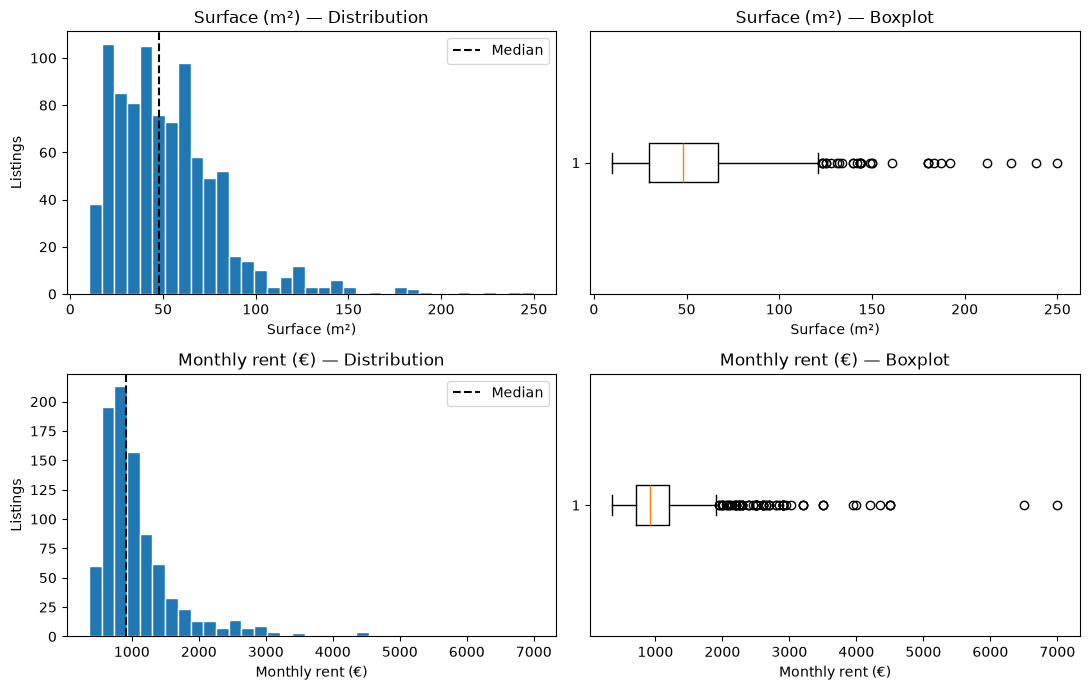

In [3]:
# Quantitative variables
numeric = ["surface_m2", "price_total_eur"]

# Basic descriptive statistics
univ = eda[numeric].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T

# Quartiles and interquartile range
univ["Q1"] = eda[numeric].quantile(0.25)
univ["Q3"] = eda[numeric].quantile(0.75)
univ["IQR"] = univ["Q3"] - univ["Q1"]

# Distribution asymmetry
univ["Skewness"] = eda[numeric].skew()

display(univ.round(2))

# Normality test
for col in numeric:
    values = eda[col].dropna()
    statistic, p_value = stats.normaltest(values)

    print(f"{col}:")
    print(f"  Normality test p-value: {p_value:.4g}")
    print(f"  Skewness: {values.skew():.2f}")


fig, axes = plt.subplots(2, 2, figsize=(11, 7))

variables = [
    ("surface_m2", "Surface (m²)"),
    ("price_total_eur", "Monthly rent (€)")
]

for row, (column, label) in enumerate(variables):

    # Histogram: distribution shape
    axes[row, 0].hist(
        eda[column].dropna(),
        bins=35,
        edgecolor="white"
    )
    axes[row, 0].axvline(
        eda[column].median(),
        color="black",
        linestyle="--",
        label="Median"
    )
    axes[row, 0].set_title(f"{label} — Distribution")
    axes[row, 0].set_xlabel(label)
    axes[row, 0].set_ylabel("Listings")
    axes[row, 0].legend()

    # Boxplot: dispersion and potential outliers
    axes[row, 1].boxplot(
        eda[column].dropna(),
        vert=False
    )
    axes[row, 1].set_title(f"{label} — Boxplot")
    axes[row, 1].set_xlabel(label)

plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>The dataset contains 845 apartments. The median surface is <b>48 m²</b>, and the median monthly rent is <b>€910</b>.</p>

<p>Both distributions are right-skewed, with a few very large or expensive apartments. The boxplots show high-value outliers, and the normality tests (p &lt; 0.05) indicate non-normal distributions.</p>

<p>Therefore, the <b>median</b> better represents typical values than the mean.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">1.2</span> Distribution of Categorical Variables
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study two categorical variables: property type
(<code>property_type_label</code>) and energy class
(<code>dpe_class</code>).

We use frequency counts, percentages, and bar charts to show
how apartments are distributed across categories.
Missing values are shown as "Unknown" in the tables.

</div>



Distribution of property_type_label:


,Listings,Share (%)
property_type_label,,
T2,293,32.2
T3,278,30.6
Studio / T1,215,23.7
T4+,123,13.5



Distribution of dpe_class:


,Listings,Share (%)
dpe_class,,
C,280,30.8
D,261,28.7
Unknown,119,13.1
B,91,10.0
E,86,9.5
A,53,5.8
F,19,2.1


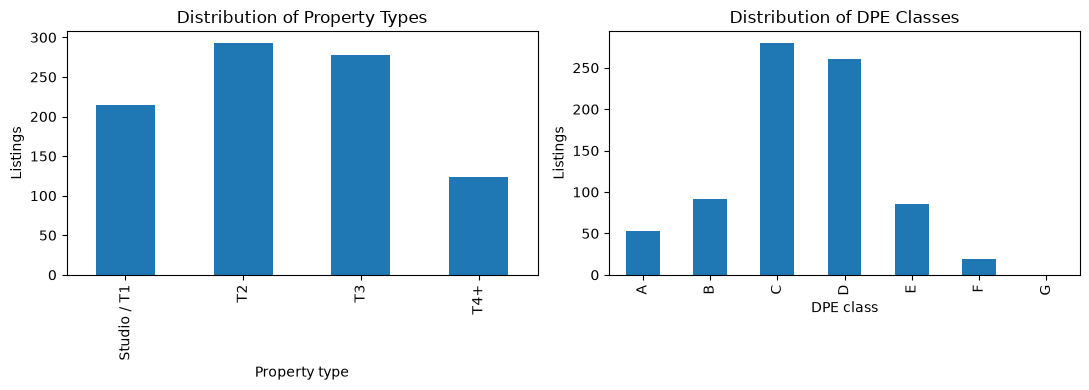

In [4]:
# Categorical variables
categorical = ["property_type_label", "dpe_class"]

for column in categorical:

    # Count each category, including missing values
    counts = (
        eda[column]
        .astype("string")
        .fillna("Unknown")
        .value_counts()
    )

    summary = pd.DataFrame({
        "Listings": counts,
        "Share (%)": 100 * counts / len(eda)
    })

    print(f"\nDistribution of {column}:")
    display(summary.round(1))


# Visual comparison of category frequencies
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

eda["property_type_label"].value_counts().reindex(
    ["Studio / T1", "T2", "T3", "T4+"],
    fill_value=0
).plot.bar(ax=axes[0])

axes[0].set_title("Distribution of Property Types")
axes[0].set_xlabel("Property type")
axes[0].set_ylabel("Listings")


eda["dpe_class"].value_counts().reindex(
    list("ABCDEFG"),
    fill_value=0
).plot.bar(ax=axes[1])

axes[1].set_title("Distribution of DPE Classes")
axes[1].set_xlabel("DPE class")
axes[1].set_ylabel("Listings")

plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>T2 (31.7%) and T3 (28.9%) are the most common property types, while T4+ is the least common (14.7%).</p>

<p>For energy classes, C (30.2%) and D (27.1%) are the most common. DPE information is missing for 16.4% of apartments, and only 17 apartments are classified F.</p>

</div>



<h2 style="color: #183f65; font-size: 23px; font-weight: 700; border-bottom: 2px solid #3b82c4; padding-bottom: 8px; margin-top: 30px; margin-bottom: 16px;">
<span style="background-color: #dceaf8; color: #164d7e; padding: 2px 8px; border-radius: 5px; display: inline-block; margin-right: 7px;">2.</span> Bivariate Analysis
</h2>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study relationships between two variables using correlation,
regression, group comparisons, and Chi-square tests, depending
on the variable types.

</div>

<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">2.1</span> Surface and Monthly Rent
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study the relationship between apartment surface
(<code>surface_m2</code>) and monthly rent
(<code>price_total_eur</code>) using correlation,
linear regression, and sensitivity analysis.

</div>

<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.1.1</span> Pearson and Spearman Correlations
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We use <b>Pearson</b> for linear correlation and
<b>Spearman</b> because it is less sensitive to outliers.
A <b>95% bootstrap confidence interval</b> is used
to check the precision of Spearman's result.

</div>



Pearson r = 0.837
Pearson p-value = 5.01e-240

Spearman rho = 0.873
Spearman p-value = 6.27e-285

Spearman 95% bootstrap CI: [0.851 0.891]


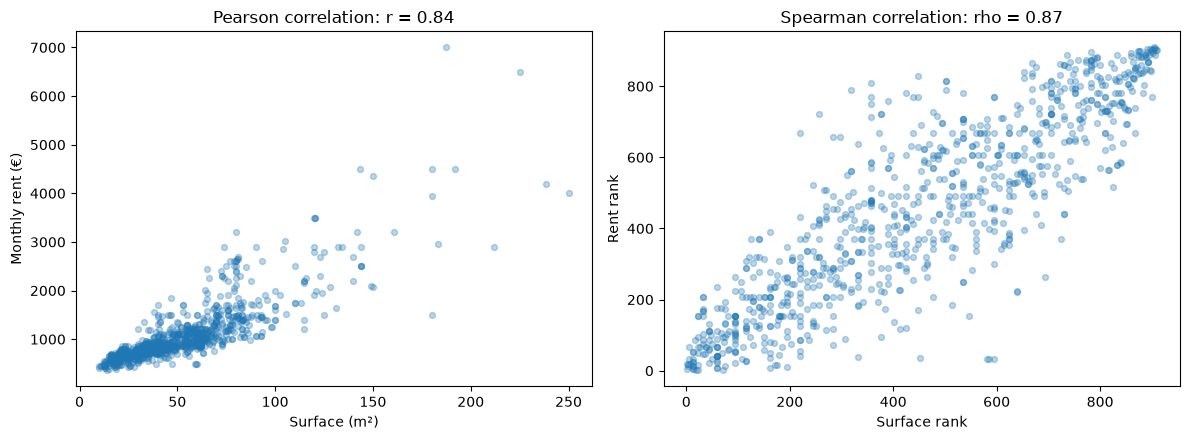

In [5]:
from scipy.stats import pearsonr, spearmanr, linregress
from scipy.stats import kruskal, mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests
import itertools

# Select valid observations
b1 = eda.dropna(subset=["surface_m2", "price_total_eur"])

x = b1["surface_m2"]
y = b1["price_total_eur"]

# Pearson: linear association
pearson = pearsonr(x, y)

# Spearman: monotonic association
spearman = spearmanr(x, y)

print(f"Pearson r = {pearson.statistic:.3f}")
print(f"Pearson p-value = {pearson.pvalue:.3g}")

print(f"\nSpearman rho = {spearman.statistic:.3f}")
print(f"Spearman p-value = {spearman.pvalue:.3g}")

# Bootstrap confidence interval for Spearman
rng = np.random.default_rng(42)

x_values = x.to_numpy()
y_values = y.to_numpy()

rhos = []

for _ in range(1000):
    indices = rng.integers(0, len(x), size=len(x))

    rho = spearmanr(
        x_values[indices],
        y_values[indices]
    ).statistic

    rhos.append(rho)

ci = np.quantile(rhos, [0.025, 0.975])

print(f"\nSpearman 95% bootstrap CI: {ci.round(3)}")

# Visualize the relationship using original values and ranks
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(x, y, alpha=0.3, s=18)
axes[0].set(
    title=f"Pearson correlation: r = {pearson.statistic:.2f}",
    xlabel="Surface (m²)",
    ylabel="Monthly rent (€)"
)

axes[1].scatter(x.rank(), y.rank(), alpha=0.3, s=18)
axes[1].set(
    title=f"Spearman correlation: rho = {spearman.statistic:.2f}",
    xlabel="Surface rank",
    ylabel="Rent rank"
)

plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Both Pearson (r = 0.841) and Spearman (ρ = 0.858) show a <b>strong positive correlation</b> between apartment surface and monthly rent: larger apartments generally have higher rents.</p>

<p>The p-values (&lt; 0.05) show that the correlations are statistically significant. The 95% bootstrap confidence interval [0.835, 0.879] confirms that the Spearman correlation is strong.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.1.2</span> Simple Linear Regression
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We use <b>Ordinary Least Squares (OLS) regression</b> to study
the linear relationship between apartment surface
(<code>surface_m2</code>) and monthly rent
(<code>price_total_eur</code>).

The <b>slope</b> estimates the rent difference for one additional m²,
while <b>R²</b> measures how much of the variation in rent
is explained by surface.

</div>


Regression equation:
Rent = 171.71 + 17.46 × Surface

Slope: 17.46 €/m²
95% CI: [16.72, 18.21]
R²: 0.701


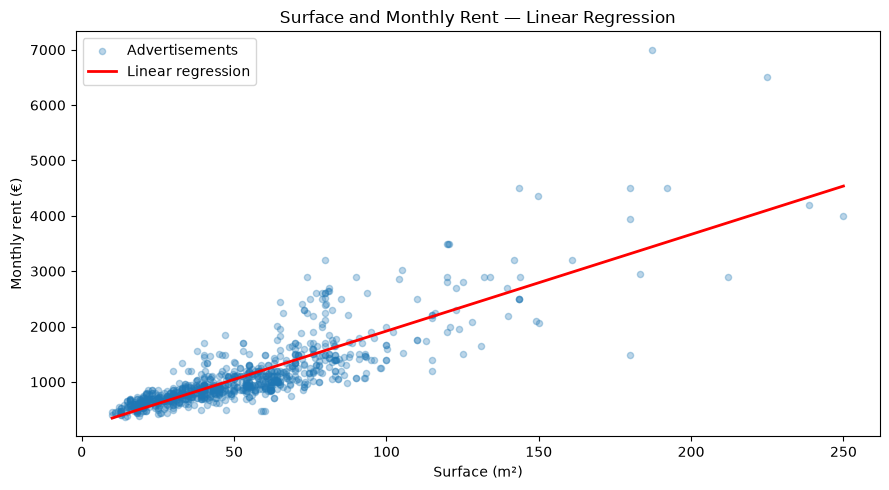

In [6]:
# Fit a simple linear regression
line = linregress(x, y)

# Predicted rent
y_fit = line.intercept + line.slope * x

# Coefficient of determination
r_squared = line.rvalue ** 2

# Classical 95% confidence interval for the slope
t_critical = stats.t.ppf(0.975, df=len(x) - 2)

slope_ci = (
    line.slope - t_critical * line.stderr,
    line.slope + t_critical * line.stderr
)

print("Regression equation:")
print(f"Rent = {line.intercept:.2f} + {line.slope:.2f} × Surface")

print(f"\nSlope: {line.slope:.2f} €/m²")
print(f"95% CI: [{slope_ci[0]:.2f}, {slope_ci[1]:.2f}]")
print(f"R²: {r_squared:.3f}")

# Scatter plot with regression line
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(x, y, alpha=0.3, s=20, label="Advertisements")

order = np.argsort(x_values)

ax.plot(
    x_values[order],
    y_fit.to_numpy()[order],
    linewidth=2,
    color="red",
    label="Linear regression"
)

ax.set(
    title="Surface and Monthly Rent — Linear Regression",
    xlabel="Surface (m²)",
    ylabel="Monthly rent (€)"
)

ax.legend()
plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>The regression shows that each additional m² is associated with an average rent increase of <b>€17.08</b>.</p>

<p>The <b>R² = 0.706</b> means that surface explains about <b>70.6% of the variation in monthly rent</b> in this linear model.</p>

<p>This confirms a strong positive relationship between surface and rent, without accounting for other apartment characteristics.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.1.3</span> Sensitivity to Extreme Values
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We recalculate <b>Pearson and Spearman correlations</b>
after temporarily excluding apartments above the 99th
percentile of surface or rent. We compare the results
to check whether extreme values affect the correlations.

</div>


In [7]:
# Find the 99th percentile for surface and rent
surface_p99 = x.quantile(0.99)
rent_p99 = y.quantile(0.99)

# Create a temporary restricted sample
restricted = b1.loc[
    (b1["surface_m2"] <= surface_p99) &
    (b1["price_total_eur"] <= rent_p99)
]

# Compare correlations before and after restriction
robustness = pd.DataFrame([
    {
        "Sample": "All advertisements",
        "n": len(b1),
        "Pearson r": pearson.statistic,
        "Spearman rho": spearman.statistic
    },
    {
        "Sample": "Without extreme high values",
        "n": len(restricted),
        "Pearson r": pearsonr(
            restricted["surface_m2"],
            restricted["price_total_eur"]
        ).statistic,
        "Spearman rho": spearmanr(
            restricted["surface_m2"],
            restricted["price_total_eur"]
        ).statistic
    }
])

display(robustness.round(3))

# Inspect the five highest rents
print("Five most expensive advertisements:")

display(
    b1.nlargest(5, "price_total_eur")[
        ["source_site", "title", "surface_m2",
         "price_total_eur", "zipcode"]
    ]
)

,Sample,n,Pearson r,Spearman rho
0,All advertisements,909,0.837,0.873
1,Without extreme high values,897,0.813,0.868


Five most expensive advertisements:


,source_site,title,surface_m2,price_total_eur,zipcode
425,bienici,LA MAJESTUEUSE - Saint Victor - Au coeur du 7e...,187.21,7000.0,13007
424,bienici,LOCATION - MEUBLEE - MARSEILLE - 7 - BOMPARD -...,225.00,6500.0,13007
558,bienici,Appartement - 144m2 - T3,143.47,4500.0,13008
778,bienici,MIAMI VIBES - Villa T4 de 192 m2 + Dépendance ...,192.00,4500.0,13012
846,bienici,Maison de 180 m² de plain-pied T6 avec garage...,180.00,4500.0,13013



<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>After excluding 11 apartments with extreme high values, Pearson decreases slightly from <b>0.841 to 0.823</b>, while Spearman remains almost unchanged (<b>0.858 to 0.853</b>).</p>

<p>This shows that the strong positive correlation between surface and monthly rent is <b>not strongly affected by extreme values</b>.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.1.4</span> Surface and Rent Within Property Types
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We calculate <b>Spearman correlation</b> between surface and monthly rent
separately for each property type (Studio/T1, T2, T3, T4+).

This checks whether the positive relationship remains within
each property type, not just across all apartments.

</div>


,Property type,Advertisements,Median surface,Median rent,Spearman rho
0,Studio / T1,215,21.000,620.000,0.620
1,T2,293,40.000,850.000,0.509
2,T3,278,63.675,1122.965,0.578
3,T4+,123,88.800,1500.000,0.774


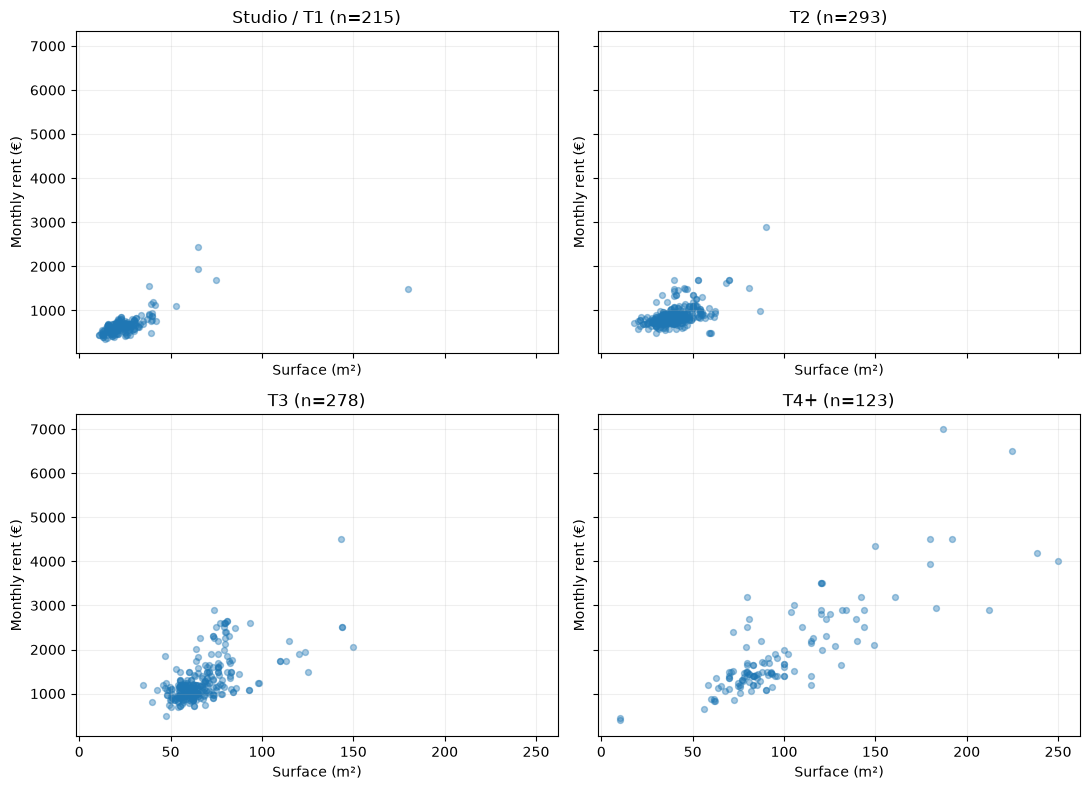

In [8]:
# Calculate correlations separately by property type
rows = []

types = ["Studio / T1", "T2", "T3", "T4+"]

for type_name in types:

    group = b1.loc[
        b1["property_type_label"] == type_name
    ]

    if len(group) < 20 or group["surface_m2"].nunique() < 2:
        continue

    rows.append({
        "Property type": type_name,
        "Advertisements": len(group),
        "Median surface": group["surface_m2"].median(),
        "Median rent": group["price_total_eur"].median(),
        "Spearman rho": spearmanr(
            group["surface_m2"],
            group["price_total_eur"]
        ).statistic
    })

property_results = pd.DataFrame(rows)
display(property_results.round(3))

# Compare relationships visually
fig, axes = plt.subplots(
    2, 2, figsize=(11, 8),
    sharex=True, sharey=True
)

for ax, type_name in zip(axes.flat, types):

    group = b1.loc[
        b1["property_type_label"] == type_name
    ]

    ax.scatter(
        group["surface_m2"],
        group["price_total_eur"],
        alpha=0.4,
        s=18
    )

    ax.set(
        title=f"{type_name} (n={len(group)})",
        xlabel="Surface (m²)",
        ylabel="Monthly rent (€)"
    )

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>The correlation between surface and monthly rent is positive for all property types. It is strongest for <b>T4+ (ρ = 0.786)</b> and weakest for <b>T2 (ρ = 0.453)</b>.</p>

<p>This shows that larger apartments generally have higher rents, even within the same property type.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.1.5</span> Rent Comparison by Surface Categories
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We divide apartments into <b>six surface categories</b> and compare
their median monthly rent and price per m².

We use medians because they are less sensitive to outliers.
This helps us see whether smaller apartments are more expensive per m².

</div>


,Advertisements,Median_surface,Median_rent,Median_price_per_m2
surface_band,,,,
<20,83,17.00,550.00,33.33
20–29,126,23.95,654.50,28.00
30–44,208,38.00,819.00,22.12
45–59,170,53.00,968.00,19.06
60–84,231,70.00,1204.59,17.71
85+,91,110.00,1950.00,16.86


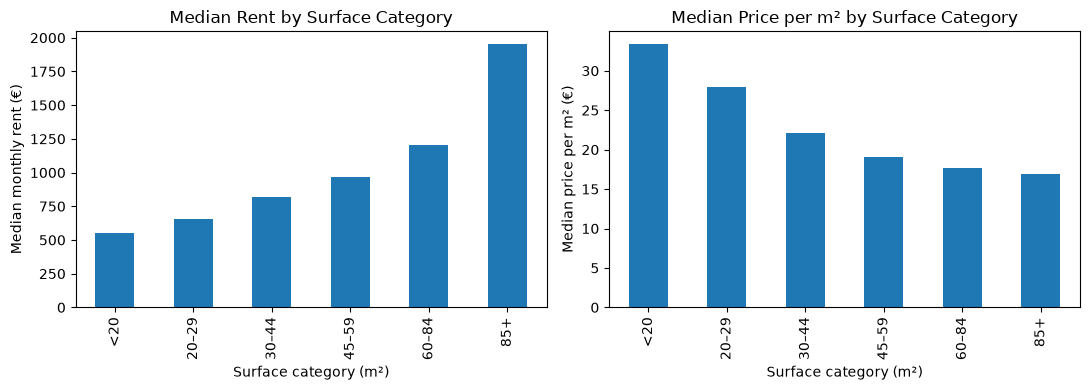

In [9]:
# Define surface categories
cut_points = [0, 20, 30, 45, 60, 85, np.inf]

band_labels = [
    "<20", "20–29", "30–44",
    "45–59", "60–84", "85+"
]

# Temporarily assign advertisements to categories
bands = pd.cut(
    b1["surface_m2"],
    bins=cut_points,
    labels=band_labels,
    right=False
)

# Calculate descriptive statistics
band_stats = (
    b1.assign(surface_band=bands)
    .groupby("surface_band", observed=True)
    .agg(
        Advertisements=("price_total_eur", "size"),
        Median_surface=("surface_m2", "median"),
        Median_rent=("price_total_eur", "median"),
        Median_price_per_m2=("price_per_m2", "median")
    )
)

display(band_stats.round(2))

# Compare median rents and median prices per m²
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

band_stats["Median_rent"].plot.bar(ax=axes[0])
axes[0].set(
    title="Median Rent by Surface Category",
    xlabel="Surface category (m²)",
    ylabel="Median monthly rent (€)"
)

band_stats["Median_price_per_m2"].plot.bar(ax=axes[1])
axes[1].set(
    title="Median Price per m² by Surface Category",
    xlabel="Surface category (m²)",
    ylabel="Median price per m² (€)"
)

plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>As apartment surface increases, <b>monthly rent increases</b>, while <b>price per m² decreases</b>.</p>

<p>Apartments under 20 m² have a median rent of €550 but cost €33.16/m², compared with €17.80/m² for apartments of 85 m² or more.</p>

<p>This shows that <b>smaller apartments are cheaper overall but more expensive per m²</b>.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">2.2</span> Rental Prices Across Geographical Zones
</h3>

<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.2.1</span> Descriptive Comparison by Zone
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare rental prices across Marseille's geographical zones using
<b>descriptive statistics</b>: median rent, median surface,
median price per m², and quartiles.

We focus on <b>price per m²</b> to compare zones while reducing
the influence of apartment size. We use medians because they are
less sensitive to outliers.

</div>


In [10]:
# Calculate descriptive statistics by geographical zone
zone_stats = eda.groupby("urban_zone").agg(
    Advertisements=("price_total_eur", "size"),
    Median_rent=("price_total_eur", "median"),
    Median_surface=("surface_m2", "median"),
    Median_price_per_m2=("price_per_m2", "median"),
    Q1_price_m2=("price_per_m2", lambda s: s.quantile(0.25)),
    Q3_price_m2=("price_per_m2", lambda s: s.quantile(0.75))
)

print("Rental statistics by geographical zone:")
display(zone_stats.round(2))

Rental statistics by geographical zone:


,Advertisements,Median_rent,Median_surface,Median_price_per_m2,Q1_price_m2,Q3_price_m2
urban_zone,,,,,,
"1. Littoral sud (7e, 8e)",182,1232.26,55.00,24.82,20.44,30.30
"2. Sud et Est (6e, 9e, 12e)",204,908.11,49.00,20.86,17.27,26.21
"3. Centre et Timone (1er, 4e, 5e)",194,850.00,39.24,22.29,17.79,28.24
"4. Euromed et Est (2e, 10e, 11e, 13e)",231,950.00,54.00,19.35,16.70,24.75
"5. Nord et 3e (3e, 14e, 15e, 16e)",98,756.09,45.50,17.45,15.37,21.90



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.2.2</span> Statistical Differences Between Geographical Zones
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We test whether <b>price per m²</b> differs across geographical zones.

We use <b>Kruskal-Wallis</b> because prices are not normally distributed,
and <b>epsilon-squared</b> to measure the size of the differences.

If the result is significant, we use <b>pairwise Mann-Whitney tests</b>
with <b>Holm correction</b> to identify which zones differ.

</div>


Kruskal-Wallis H = 89.31
p-value = 1.85e-18
Epsilon-squared ≈ 0.094

Pairwise comparisons:


,Zone 1,Zone 2,Median difference (€/m²),p_raw,p_Holm
3,"1. Littoral sud (7e, 8e)","5. Nord et 3e (3e, 14e, 15e, 16e)",7.370,0.0000,0.0000
2,"1. Littoral sud (7e, 8e)","4. Euromed et Est (2e, 10e, 11e, 13e)",5.475,0.0000,0.0000
8,"3. Centre et Timone (1er, 4e, 5e)","5. Nord et 3e (3e, 14e, 15e, 16e)",4.835,0.0000,0.0000
0,"1. Littoral sud (7e, 8e)","2. Sud et Est (6e, 9e, 12e)",3.970,0.0000,0.0000
6,"2. Sud et Est (6e, 9e, 12e)","5. Nord et 3e (3e, 14e, 15e, 16e)",3.400,0.0000,0.0000
7,"3. Centre et Timone (1er, 4e, 5e)","4. Euromed et Est (2e, 10e, 11e, 13e)",2.940,0.0001,0.0003
9,"4. Euromed et Est (2e, 10e, 11e, 13e)","5. Nord et 3e (3e, 14e, 15e, 16e)",1.895,0.0013,0.0054
1,"1. Littoral sud (7e, 8e)","3. Centre et Timone (1er, 4e, 5e)",2.535,0.0052,0.0155
4,"2. Sud et Est (6e, 9e, 12e)","3. Centre et Timone (1er, 4e, 5e)",-1.435,0.0283,0.0566
5,"2. Sud et Est (6e, 9e, 12e)","4. Euromed et Est (2e, 10e, 11e, 13e)",1.505,0.0561,0.0566


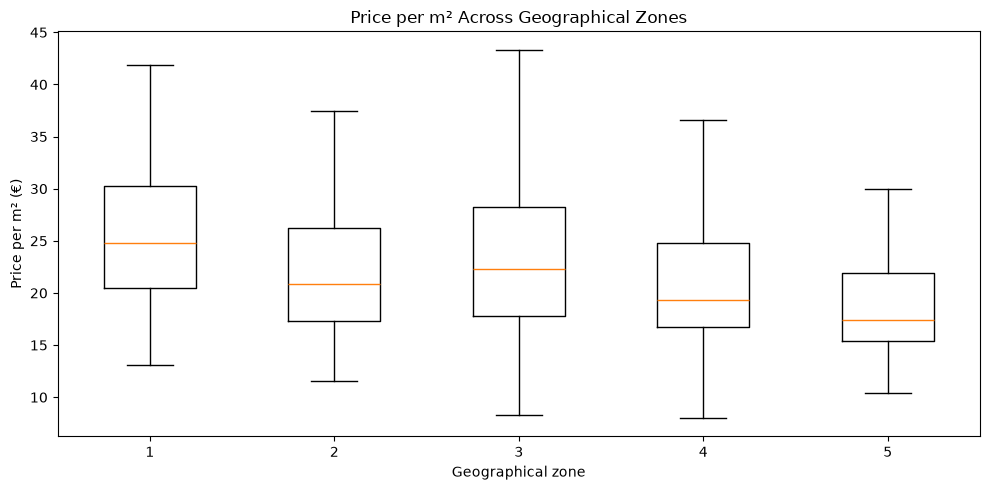

In [11]:
# Prepare price-per-m² observations by zone
zone_groups = [
    (name, group["price_per_m2"].dropna())
    for name, group in eda.groupby("urban_zone")
    if group["price_per_m2"].notna().sum() >= 10
]

if len(zone_groups) >= 3:

    # Global Kruskal-Wallis test
    H, p = kruskal(
        *[values for _, values in zone_groups]
    )

    n_total = sum(len(values) for _, values in zone_groups)
    k = len(zone_groups)

    # Approximate effect size
    epsilon_sq = max(
        0, (H - k + 1) / (n_total - k)
    )

    print(f"Kruskal-Wallis H = {H:.2f}")
    print(f"p-value = {p:.3g}")
    print(f"Epsilon-squared ≈ {epsilon_sq:.3f}")

    # Pairwise Mann-Whitney comparisons
    pairwise = []

    for (name_a, a), (name_b, b) in itertools.combinations(zone_groups, 2):

        U, p_pair = mannwhitneyu(
            a, b, alternative="two-sided"
        )

        pairwise.append({
            "Zone 1": name_a,
            "Zone 2": name_b,
            "Median difference (€/m²)": a.median() - b.median(),
            "p_raw": p_pair
        })

    posthoc = pd.DataFrame(pairwise)

    # Adjust for multiple testing
    posthoc["p_Holm"] = multipletests(
        posthoc["p_raw"],
        method="holm"
    )[1]

    print("\nPairwise comparisons:")
    display(posthoc.sort_values("p_Holm").round(4))

    # Boxplot by zone
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.boxplot(
        [values for _, values in zone_groups],
        tick_labels=[name.split(".")[0] for name, _ in zone_groups],
        showfliers=False
    )

    ax.set(
        title="Price per m² Across Geographical Zones",
        xlabel="Geographical zone",
        ylabel="Price per m² (€)"
    )

    plt.tight_layout()
    plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Price per m² differs across geographical zones. <b>Littoral Sud</b> has the highest median (€23.38/m²), while <b>Nord et 3e</b> has the lowest (€17.91/m²).</p>

<p>After Holm correction, <b>7 out of 10 comparisons are statistically significant</b>. The largest median difference is between Littoral Sud and Nord et 3e (€5.47/m²).</p>

<p>These comparisons do not account for differences in apartment size or property type.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.2.3</span> Arrondissement-level Check
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare the <b>median price per m²</b> across Marseille's
16 arrondissements to check for differences within our five zones.

We use <b>Kruskal-Wallis</b> to test price differences, including
only arrondissements with at least 10 advertisements.

</div>


In [12]:
arrondissement_stats = eda.groupby("arrondissement").agg(
    n=("price_per_m2", "count"),
    median_price_m2=("price_per_m2", "median"),
    median_rent=("price_total_eur", "median"),
    median_surface=("surface_m2", "median")
).sort_index()
print("Descriptive comparison across all arrondissements:")
display(arrondissement_stats.round(2))

arr_groups = [(name, g["price_per_m2"].dropna())
              for name, g in eda.groupby("arrondissement")
              if g["price_per_m2"].notna().sum() >= 10]
small_arr = arrondissement_stats.index[arrondissement_stats["n"] < 10].tolist()
print("Groups with fewer than 10 observations (described only):", small_arr)
if len(arr_groups) >= 3:
    H_arr, p_arr = kruskal(*[values for _, values in arr_groups])
    print(f"Kruskal-Wallis across sufficiently populated arrondissements: "
          f"H={H_arr:.2f}, p={p_arr:.3g}")

Descriptive comparison across all arrondissements:


,n,median_price_m2,median_rent,median_surface
arrondissement,,,,
1,83,22.88,880.00,42.00
2,69,22.71,950.00,42.70
3,36,17.59,721.00,45.11
4,43,20.00,800.00,43.00
5,68,23.56,800.00,33.00
6,78,23.38,845.00,40.00
7,49,28.44,1270.00,47.00
8,133,24.29,1220.51,58.00
9,81,20.36,908.22,52.71


Groups with fewer than 10 observations (described only): [16]
Kruskal-Wallis across sufficiently populated arrondissements: H=139.87, p=7.55e-23



<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Price per m² varies across arrondissements. The <b>7th</b> has the highest median (€26.94/m²), while the <b>14th</b> has the lowest (€14.86/m²).</p>

<p>The Kruskal-Wallis test (p &lt; 0.05) shows significant differences between arrondissements. This also shows that prices can vary <b>within the same geographical zone</b>.</p>

<p>The 16th arrondissement was excluded from the test because it has only 4 advertisements.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">2.3</span> Relationships Involving Categorical Variables
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study relationships involving categorical variables,
using statistical methods based on the variable types.

</div>

<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.3.1</span> Relationship Between Location and Property Type
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study whether <b>property types</b> are distributed differently
across geographical zones.

We use a <b>contingency table</b> to compare distributions,
a <b>Chi-square test</b> to test the association,
and <b>Cramér's V</b> to measure its strength.

</div>


Counts:


property_type_label,Studio / T1,T2,T3,T4+
urban_zone,,,,
"1. Littoral sud (7e, 8e)",28,63,61,30
"2. Sud et Est (6e, 9e, 12e)",52,56,67,29
"3. Centre et Timone (1er, 4e, 5e)",66,66,43,19
"4. Euromed et Est (2e, 10e, 11e, 13e)",44,76,80,31
"5. Nord et 3e (3e, 14e, 15e, 16e)",25,32,27,14



Percentages by zone:


property_type_label,Studio / T1,T2,T3,T4+
urban_zone,,,,
"1. Littoral sud (7e, 8e)",15.4,34.6,33.5,16.5
"2. Sud et Est (6e, 9e, 12e)",25.5,27.5,32.8,14.2
"3. Centre et Timone (1er, 4e, 5e)",34.0,34.0,22.2,9.8
"4. Euromed et Est (2e, 10e, 11e, 13e)",19.0,32.9,34.6,13.4
"5. Nord et 3e (3e, 14e, 15e, 16e)",25.5,32.7,27.6,14.3



Chi-square = 28.75
Degrees of freedom = 12
p-value = 0.00429
Cramér's V = 0.103
Expected frequencies below 5: 0 / 20


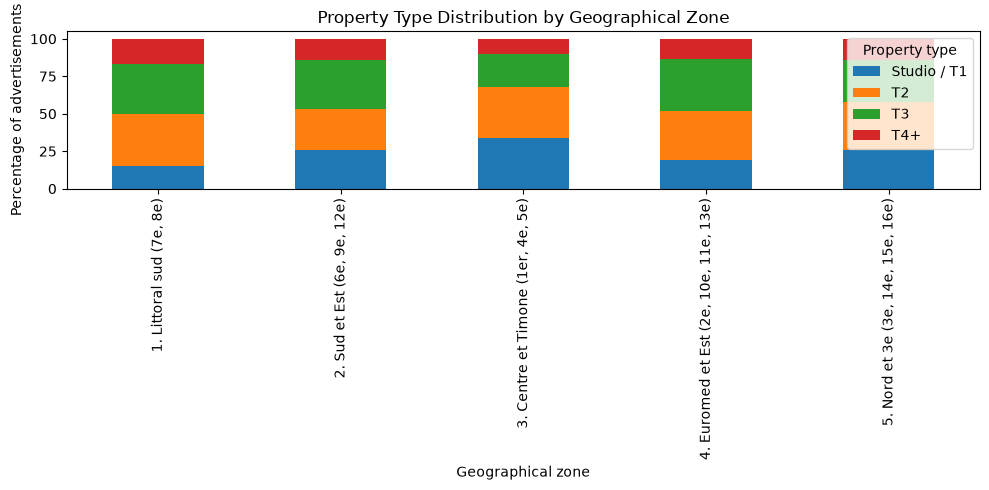

In [13]:
# Contingency table: zone × property type
contingency = pd.crosstab(
    eda["urban_zone"],
    eda["property_type_label"]
)

print("Counts:")
display(contingency)

# Percentages within each geographical zone
percentages = 100 * contingency.div(
    contingency.sum(axis=1),
    axis=0
)

print("\nPercentages by zone:")
display(percentages.round(1))

# Chi-square test
chi2, p_chi2, dof, expected = chi2_contingency(contingency)

# Cramér's V effect size
n = contingency.to_numpy().sum()

v = np.sqrt(
    chi2 / (
        n * min(
            contingency.shape[0] - 1,
            contingency.shape[1] - 1
        )
    )
)

print(f"\nChi-square = {chi2:.2f}")
print(f"Degrees of freedom = {dof}")
print(f"p-value = {p_chi2:.3g}")
print(f"Cramér's V = {v:.3f}")

print(
    "Expected frequencies below 5:",
    (expected < 5).sum(),
    "/", expected.size
)

# Visual comparison of property-type proportions
percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Property Type Distribution by Geographical Zone")
plt.xlabel("Geographical zone")
plt.ylabel("Percentage of advertisements")
plt.legend(title="Property type")
plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Property types vary across geographical zones. <b>Centre et Timone</b> has the highest percentage of studios/T1 (35.3%), while <b>Littoral Sud</b> has the lowest (18.3%).</p>

<p>The Chi-square test (p = 0.0147) shows a statistically significant association between zone and property type. However, <b>Cramér's V = 0.099</b> indicates that this association is weak.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.3.2</span> DPE and Price per m²
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare <b>price per m²</b> across DPE energy classes
using medians and IQR.

We use <b>Kruskal-Wallis</b> to test for differences,
including only classes with at least 20 apartments
because some classes have very few observations.

</div>


In [14]:
dpe_summary = eda.dropna(subset=["dpe_class", "price_per_m2"]).groupby("dpe_class").agg(
    n=("price_per_m2", "size"),
    median_price_m2=("price_per_m2", "median"),
    Q1=("price_per_m2", lambda s: s.quantile(.25)),
    Q3=("price_per_m2", lambda s: s.quantile(.75))
).reindex(list("ABCDEFG"))
print("DPE: unadjusted price/m² comparison (missing DPE excluded):")
display(dpe_summary.round(2))

dpe_groups = [(label, eda.loc[eda["dpe_class"].eq(label), "price_per_m2"].dropna())
              for label in "ABCDEFG"
              if eda["dpe_class"].eq(label).sum() >= 20]
print("Groups used in Kruskal-Wallis (at least 20 observations):", [a for a, _ in dpe_groups])
if len(dpe_groups) >= 3:
    H_dpe, p_dpe = kruskal(*[v for _, v in dpe_groups])
    print(f"Kruskal-Wallis H={H_dpe:.2f}, p={p_dpe:.3g}")

DPE: unadjusted price/m² comparison (missing DPE excluded):


,n,median_price_m2,Q1,Q3
dpe_class,,,,
A,53.0,20.83,17.90,26.45
B,91.0,21.18,16.62,26.22
C,280.0,21.16,17.37,25.98
D,261.0,20.57,16.96,26.27
E,86.0,20.67,17.12,28.33
F,19.0,22.62,18.90,26.86
G,NaN,NaN,NaN,NaN


Groups used in Kruskal-Wallis (at least 20 observations): ['A', 'B', 'C', 'D', 'E']
Kruskal-Wallis H=1.30, p=0.862



<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Median prices per m² are similar across DPE classes A to E, ranging from €20.18 to €21.82.</p>

<p>The <b>Kruskal-Wallis test (p = 0.653)</b> shows no statistically significant difference in price per m² between these classes.</p>

<p>Class F was excluded from the test because it has only 17 apartments, and class G has no observations.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">2.3.3</span> Rental Charges by Property Type
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare <b>charges as a percentage of rent</b> across
property types, using only observed charges.

We calculate descriptive statistics and check normality
and variance equality to choose between <b>ANOVA,
Welch ANOVA, or Kruskal-Wallis</b>.

</div>


Observed-charge sample only: 659 listings


,count,mean,median,std
property_type_label,,,,
Studio / T1,144,8.80,7.70,4.82
T2,227,9.16,8.50,4.50
T3,206,9.95,8.90,5.13
T4+,82,10.38,9.45,5.85


Residual normality test: p=7.492e-24
Brown-Forsythe variance check: p=0.01244
Selected method: Kruskal-Wallis (rank-based group comparison)
Test statistic=8.100, p=0.04399
Interpret observed differences, not causality; listing independence is not guaranteed.


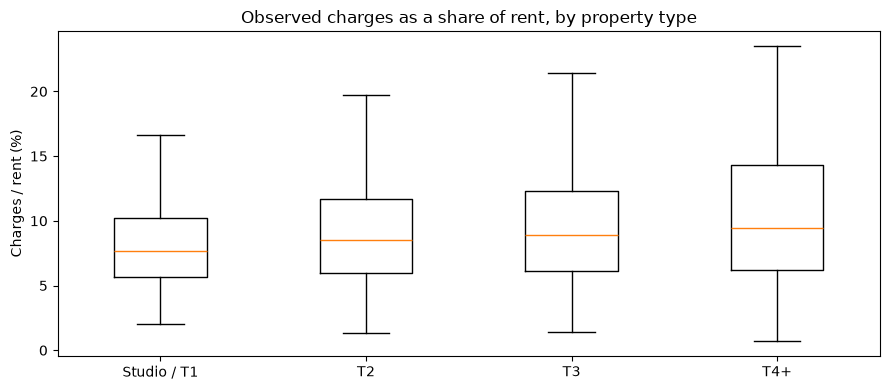

In [15]:
# Source: teammate's ANOVA / Kruskal comparison; updated for the cleaned 845-row CSV.
# Do not use imputed charges as independently observed evidence.
charge_obs = eda.loc[~eda["charges_eur_estimated"]].dropna(
    subset=["charges_share_pct", "property_type_label"]
).copy()
charge_groups = {
    name: g["charges_share_pct"].to_numpy(dtype=float)
    for name, g in charge_obs.groupby("property_type_label")
    if len(g) >= 20
}
print("Observed-charge sample only:", len(charge_obs), "listings")
display(charge_obs.groupby("property_type_label")["charges_share_pct"].agg(
    ["count", "mean", "median", "std"]
).round(2))
if len(charge_groups) >= 3:
    vals = list(charge_groups.values())
    residuals = np.concatenate([v - v.mean() for v in vals])
    p_normal = stats.normaltest(residuals).pvalue
    p_variance = stats.levene(*vals, center="median").pvalue
    print(f"Residual normality test: p={p_normal:.4g}")
    print(f"Brown-Forsythe variance check: p={p_variance:.4g}")
    if p_normal >= .05 and p_variance >= .05:
        result = stats.f_oneway(*vals)
        method = "Classical one-way ANOVA (comparison of means)"
    elif p_normal >= .05 and p_variance < .05:
        # Available in SciPy >= 1.16; use a documented implementation for older versions.
        try:
            result = stats.f_oneway(*vals, equal_var=False)
            method = "Welch ANOVA (comparison of means with unequal variances)"
        except TypeError:
            result = None
            method = "Welch ANOVA indicated; update SciPy to >=1.16 to run it"
    else:
        result = stats.kruskal(*vals)
        method = "Kruskal-Wallis (rank-based group comparison)"
    print("Selected method:", method)
    if result is not None:
        print(f"Test statistic={result.statistic:.3f}, p={result.pvalue:.4g}")
    print("Interpret observed differences, not causality; listing independence is not guaranteed.")

fig, ax = plt.subplots(figsize=(9, 4))
order_types = [t for t in ["Studio / T1", "T2", "T3", "T4+"] if t in charge_groups]
ax.boxplot([charge_groups[t] for t in order_types], tick_labels=order_types, showfliers=False)
ax.set(title="Observed charges as a share of rent, by property type", ylabel="Charges / rent (%)")
plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Based on 591 apartments with observed charges, the median share of charges increases from <b>7.70% for Studio/T1</b> to <b>10.60% for T4+</b>.</p>

<p>The <b>Kruskal-Wallis test (p = 0.0113)</b> shows a statistically significant difference in charge percentages between property types, but does not identify which types differ.</p>

</div>


<h2 style="color: #183f65; font-size: 23px; font-weight: 700; border-bottom: 2px solid #3b82c4; padding-bottom: 8px; margin-top: 30px; margin-bottom: 16px;">
<span style="background-color: #dceaf8; color: #164d7e; padding: 2px 8px; border-radius: 5px; display: inline-block; margin-right: 7px;">3.</span> Multivariate Analysis
</h2>
<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study relationships between three or more variables at the same time.

</div>

<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.1</span> Price per m² by Zone and Property Type
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare the <b>median price per m²</b> across geographical zones
for each property type (Studio/T1, T2, T3, T4+).

We use <b>grouped medians</b> to see whether price differences
between zones remain within the same property type.
We also check the number of apartments in each group.

</div>


In [16]:
# zone (nominal) × type (categorical) × price/m² (numeric)
price_by_zone_type = eda.groupby(["urban_zone", "property_type_label"], observed=True).agg(
    n=("price_per_m2", "count"),
    median_price_m2=("price_per_m2", "median"),
    median_surface=("surface_m2", "median")
).reset_index()
print("Group sizes and median prices:")
display(price_by_zone_type.round(2))

# Hide unreliable small-group medians in the visual only; the source rows stay unchanged.
reliable = price_by_zone_type.copy()
reliable.loc[reliable["n"] < 10, "median_price_m2"] = np.nan
pivot = reliable.pivot(index="urban_zone", columns="property_type_label", values="median_price_m2")
counts = price_by_zone_type.pivot(index="urban_zone", columns="property_type_label", values="n")
print("Number of advertisements in each combination:")
display(counts)
print("Median price/m² (groups with n<10 displayed as blank):")
display(pivot.round(2))


Group sizes and median prices:


,urban_zone,property_type_label,n,median_price_m2,median_surface
0,"1. Littoral sud (7e, 8e)",Studio / T1,28,31.51,21.00
1,"1. Littoral sud (7e, 8e)",T2,63,24.29,40.00
2,"1. Littoral sud (7e, 8e)",T3,61,22.02,71.00
3,"1. Littoral sud (7e, 8e)",T4+,30,20.05,98.68
4,"2. Sud et Est (6e, 9e, 12e)",Studio / T1,52,28.12,20.01
5,"2. Sud et Est (6e, 9e, 12e)",T2,56,21.75,40.00
6,"2. Sud et Est (6e, 9e, 12e)",T3,67,17.10,63.00
7,"2. Sud et Est (6e, 9e, 12e)",T4+,29,17.55,90.87
8,"3. Centre et Timone (1er, 4e, 5e)",Studio / T1,66,28.22,21.34
9,"3. Centre et Timone (1er, 4e, 5e)",T2,66,21.79,40.00


Number of advertisements in each combination:


property_type_label,Studio / T1,T2,T3,T4+
urban_zone,,,,
"1. Littoral sud (7e, 8e)",28,63,61,30
"2. Sud et Est (6e, 9e, 12e)",52,56,67,29
"3. Centre et Timone (1er, 4e, 5e)",66,66,43,19
"4. Euromed et Est (2e, 10e, 11e, 13e)",44,76,80,31
"5. Nord et 3e (3e, 14e, 15e, 16e)",25,32,27,14


Median price/m² (groups with n<10 displayed as blank):


property_type_label,Studio / T1,T2,T3,T4+
urban_zone,,,,
"1. Littoral sud (7e, 8e)",31.51,24.29,22.02,20.05
"2. Sud et Est (6e, 9e, 12e)",28.12,21.75,17.10,17.55
"3. Centre et Timone (1er, 4e, 5e)",28.22,21.79,17.81,16.88
"4. Euromed et Est (2e, 10e, 11e, 13e)",29.60,20.94,17.00,18.50
"5. Nord et 3e (3e, 14e, 15e, 16e)",23.51,18.12,15.22,14.47



<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p><b>Studios/T1 have the highest median price per m²</b> in every zone, while larger apartments generally have lower prices per m².</p>

<p>Prices also differ by location within the same property type. For example, T2 apartments cost <b>€24.29/m² in Littoral Sud</b> compared with <b>€18.13/m² in Nord et 3e</b>.</p>

<p>This shows that both property type and geographical zone are associated with price per m². However, these comparisons do not control for exact surface or other apartment characteristics.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.2</span> Furnished Status, Zone and Price per m²
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare <b>price per m²</b> between furnished and unfurnished
apartments within each geographical zone.

We use a <b>split violin plot</b> to compare price distributions
and a summary table to compare medians.

Only apartments with known furnished status are included.

</div>


Known furnished status only. Check subgroup counts before interpreting:


n  median_price_m2  \
urban_zone                            Furnished status                         
1. Littoral sud (7e, 8e)              Furnished          90            27.51   
                                      Unfurnished        46            22.23   
2. Sud et Est (6e, 9e, 12e)           Furnished          84            23.44   
                                      Unfurnished        59            17.74   
3. Centre et Timone (1er, 4e, 5e)     Furnished         119            24.26   
                                      Unfurnished        34            16.92   
4. Euromed et Est (2e, 10e, 11e, 13e) Furnished         104            22.12   
                                      Unfurnished        57            18.31   
5. Nord et 3e (3e, 14e, 15e, 16e)     Furnished          43            20.15   
                                      Unfurnished        26            16.33   

                                                        median_surface  
urban_zone                            Furnished status                  
1. Littoral sud (7e, 8e)              Furnished                  55.00  
                                      Unfurnished                58.00  
2. Sud et Est (6e, 9e, 12e)           Furnished                  41.00  
                                      Unfurnished                61.00  
3. Centre et Timone (1er, 4e, 5e)     Furnished                  33.93  
                                      Unfurnished                59.61  
4. Euromed et Est (2e, 10e, 11e, 13e) Furnished                  39.92  
                                      Unfurnished                56.00  
5. Nord et 3e (3e, 14e, 15e, 16e)     Furnished                  40.00  
                                      Unfurnished                51.23

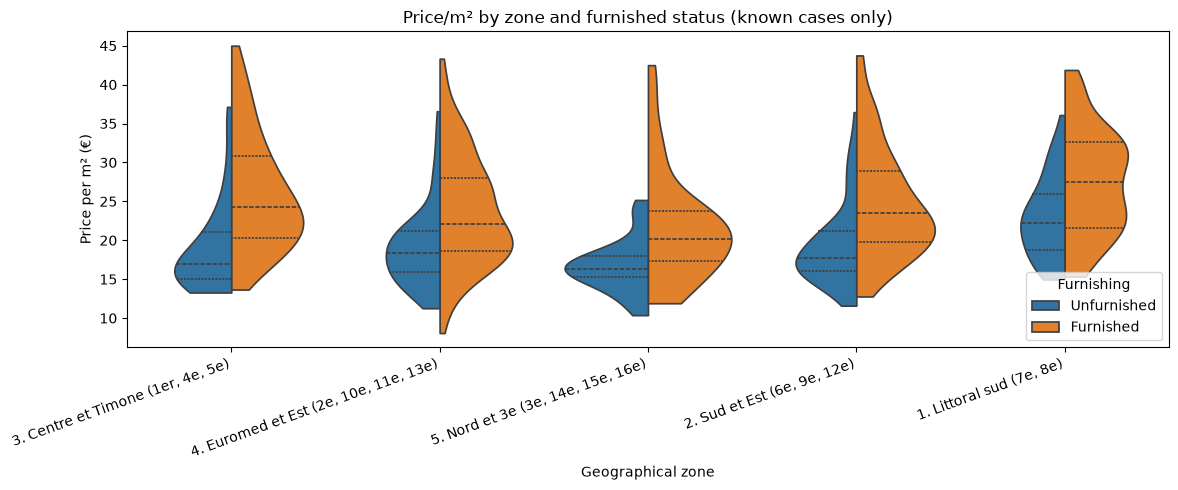

In [17]:
#Split violins: zone × furnished binary × price/m²
import seaborn as sns
split_data = eda.loc[eda["is_furnished_binary"].isin([0, 1])].copy()
split_data["Furnished status"] = split_data["is_furnished_binary"].map({0: "Unfurnished", 1: "Furnished"})
zone_furn_summary = split_data.groupby(["urban_zone", "Furnished status"]).agg(
    n=("price_per_m2", "count"),
    median_price_m2=("price_per_m2", "median"),
    median_surface=("surface_m2", "median")
)
print("Known furnished status only. Check subgroup counts before interpreting:")
display(zone_furn_summary.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(
    data=split_data, x="urban_zone", y="price_per_m2", hue="Furnished status",
    hue_order=["Unfurnished", "Furnished"], split=True, inner="quart", cut=0, ax=ax
)
ax.set(title="Price/m² by zone and furnished status (known cases only)",
       xlabel="Geographical zone", ylabel="Price per m² (€)")
ax.tick_params(axis="x", labelrotation=20)
for label in ax.get_xticklabels():label.set_ha("right")
ax.legend(title="Furnishing")
plt.tight_layout()
plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p><b>Furnished apartments have higher median prices per m²</b> than unfurnished apartments in all five zones.</p>

<p>The largest difference is in <b>Centre et Timone</b> (€24.08/m² vs €16.92/m²).</p>

<p>However, furnished apartments also tend to be smaller. Therefore, the price differences cannot be explained by furnished status alone.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.3</span> DPE, Furnished Status and Price per m²
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare <b>price per m²</b> across DPE classes for furnished
and unfurnished apartments.

We use <b>grouped medians and bar charts</b> to compare prices,
including only groups with at least 10 apartments in the chart.

Apartments with missing DPE or furnished status are excluded.

</div>


All known DPE × furnishing combinations (including small groups):


,dpe_class,Furnishing,n,median_price_m2
0,A,Furnished,19,22.40
1,A,Unfurnished,17,20.32
2,B,Furnished,43,23.44
3,B,Unfurnished,28,17.16
4,C,Furnished,124,24.10
5,C,Unfurnished,80,18.06
6,D,Furnished,132,23.63
7,D,Unfurnished,62,17.36
8,E,Furnished,37,27.06
9,E,Unfurnished,21,20.75


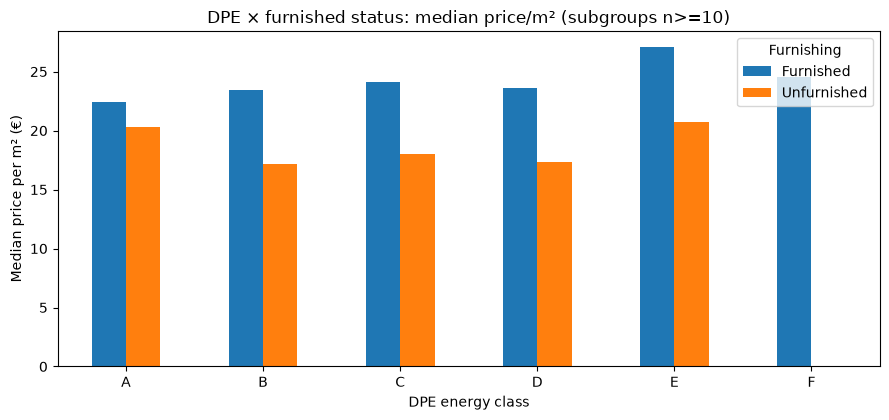

In [18]:
#  DPE (ordinal categories) × furnished status (binary) × price per m²
energy = eda.dropna(subset=["dpe_class", "is_furnished_binary", "price_per_m2"]).copy()
energy = energy.loc[energy["dpe_class"].isin(list("ABCDEFG")) &
                    energy["is_furnished_binary"].isin([0, 1])]
energy["Furnishing"] = energy["is_furnished_binary"].map({0:"Unfurnished",1:"Furnished"})
energy_summary = energy.groupby(["dpe_class", "Furnishing"]).agg(
    n=("price_per_m2", "count"), median_price_m2=("price_per_m2", "median")
).reset_index()
print("All known DPE × furnishing combinations (including small groups):")
display(energy_summary.round(2))
# Show only cells with n >= 10 in the chart. No automatic deletion from CSV.
reliable_energy = energy_summary.loc[energy_summary["n"] >= 10].copy()
pivot_energy = reliable_energy.pivot(index="dpe_class", columns="Furnishing", values="median_price_m2")
pivot_energy = pivot_energy.reindex(list("ABCDEFG")).dropna(how="all")
pivot_energy.plot.bar(figsize=(9,4.3))
plt.title("DPE × furnished status: median price/m² (subgroups n>=10)")
plt.xlabel("DPE energy class"); plt.ylabel("Median price per m² (€)")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p><b>Furnished apartments have higher median prices per m²</b> than unfurnished apartments in every DPE class from A to E.</p>

<p>For example, in class D, furnished apartments cost <b>€23.78/m²</b>, compared with <b>€17.48/m²</b> for unfurnished apartments.</p>

<p>There is no clear pattern showing that better DPE classes have higher prices. These comparisons do not account for surface or location, and class F has too few observations for a reliable comparison.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.4</span> Upfront Costs by Zone and Furnished Status
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare <b>upfront housing costs</b> across geographical zones
for furnished and unfurnished apartments.

We calculate <b>upfront cost / monthly rent</b> to express
the initial payment in months of rent, then compare
the <b>median ratios</b> for each group.

Only apartments with available cost information are included.

</div>


Valid cost + furnishing observations: 435 out of 909
Overall upfront-cost availability by zone:


,total,known,completeness
urban_zone,,,
"1. Littoral sud (7e, 8e)",182,101,55.5
"2. Sud et Est (6e, 9e, 12e)",204,121,59.3
"3. Centre et Timone (1er, 4e, 5e)",194,120,61.9
"4. Euromed et Est (2e, 10e, 11e, 13e)",231,131,56.7
"5. Nord et 3e (3e, 14e, 15e, 16e)",98,56,57.1


Entry-cost burden by zone and furnishing status:


n  median_rent  \
urban_zone                            furnishing                     
1. Littoral sud (7e, 8e)              Furnished    47      1270.00   
                                      Unfurnished  35      1070.00   
2. Sud et Est (6e, 9e, 12e)           Furnished    45       880.00   
                                      Unfurnished  50       970.00   
3. Centre et Timone (1er, 4e, 5e)     Furnished    70       755.00   
                                      Unfurnished  33       865.00   
4. Euromed et Est (2e, 10e, 11e, 13e) Furnished    66       866.00   
                                      Unfurnished  43       876.59   
5. Nord et 3e (3e, 14e, 15e, 16e)     Furnished    26       760.50   
                                      Unfurnished  20       786.50   

                                                   median_upfront  \
urban_zone                            furnishing                    
1. Littoral sud (7e, 8e)              Furnished            4036.0   
                                      Unfurnished          2831.0   
2. Sud et Est (6e, 9e, 12e)           Furnished            2967.0   
                                      Unfurnished          2574.0   
3. Centre et Timone (1er, 4e, 5e)     Furnished            2510.5   
                                      Unfurnished          2435.0   
4. Euromed et Est (2e, 10e, 11e, 13e) Furnished            2306.5   
                                      Unfurnished          2293.0   
5. Nord et 3e (3e, 14e, 15e, 16e)     Furnished            2501.5   
                                      Unfurnished          2198.0   

                                                   median_months  
urban_zone                            furnishing                  
1. Littoral sud (7e, 8e)              Furnished             3.28  
                                      Unfurnished           2.50  
2. Sud et Est (6e, 9e, 12e)           Furnished             3.38  
                                      Unfurnished           2.65  
3. Centre et Timone (1er, 4e, 5e)     Furnished             3.33  
                                      Unfurnished           2.69  
4. Euromed et Est (2e, 10e, 11e, 13e) Furnished             3.20  
                                      Unfurnished           2.59  
5. Nord et 3e (3e, 14e, 15e, 16e)     Furnished             3.43  
                                      Unfurnished           2.71

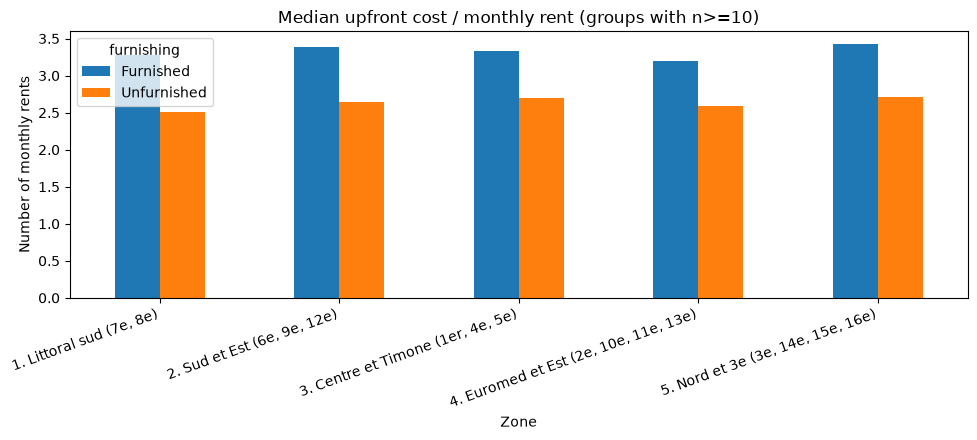

In [19]:
# Entry-cost burden by zone and furnished status
finance = eda.dropna(subset=["upfront_move_in_cost_eur", "price_total_eur", "urban_zone", "is_furnished_binary"]).copy()
finance = finance.loc[finance["price_total_eur"].gt(0)]
finance["upfront_to_rent"] = finance["upfront_move_in_cost_eur"] / finance["price_total_eur"]
finance["furnishing"] = finance["is_furnished_binary"].map({0: "Unfurnished", 1: "Furnished"})
print(f"Valid cost + furnishing observations: {len(finance)} out of {len(eda)}")
print("Overall upfront-cost availability by zone:")
display(eda.groupby("urban_zone")["upfront_move_in_cost_eur"].agg(
    total="size", known="count", completeness=lambda x: round(100*x.notna().mean(),1)
))
cost_summary = finance.groupby(["urban_zone", "furnishing"]).agg(
    n=("upfront_to_rent", "size"),
    median_rent=("price_total_eur", "median"),
    median_upfront=("upfront_move_in_cost_eur", "median"),
    median_months=("upfront_to_rent", "median")
)
print("Entry-cost burden by zone and furnishing status:")
display(cost_summary.round(2))

# Simple grouped bar plot: suppress small cells from the figure, not from the table.
plot_cost = cost_summary.reset_index()
plot_cost.loc[plot_cost["n"] < 10, "median_months"] = np.nan
pivot_cost = plot_cost.pivot(index="urban_zone", columns="furnishing", values="median_months")
pivot_cost.plot.bar(figsize=(10,4.5))
plt.title("Median upfront cost / monthly rent (groups with n>=10)")
plt.ylabel("Number of monthly rents")
plt.xlabel("Zone")
plt.xticks(rotation=20, ha="right")
plt.tight_layout();plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p><b>Furnished apartments have higher upfront costs relative to monthly rent</b> in all five zones.</p>

<p>The median ratio ranges from <b>2.92 to 3.36 months</b> for furnished apartments, compared with <b>2.50 to 2.73 months</b> for unfurnished apartments.</p>

<p><b>Littoral Sud</b> has the highest median upfront costs in euros (€3,541 for furnished apartments), while <b>Sud et Est</b> has the highest relative cost for furnished apartments (3.36 months).</p>

<p>These results only include apartments with available cost information.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.5</span> Reported Amenities and Price per m²
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study the relationship between <b>reported amenities</b> and
<b>price per m²</b>, taking missing information into account.

We use <b>grouped medians and a heatmap</b> to compare prices
for apartments with the same number of known amenity fields.

Groups with fewer than 10 apartments are hidden from the heatmap.

</div>


Apartments analyzed: 753


,amenities_known_count,amenity_score,n,median_price_m2
0,1,0.0,39,21.14
1,1,1.0,268,23.19
2,2,0.0,37,16.72
3,2,1.0,127,20.32
4,2,2.0,133,24.80
5,3,0.0,7,18.82
6,3,1.0,26,17.02
7,3,2.0,62,19.91
8,3,3.0,28,26.64
9,4,1.0,2,25.42


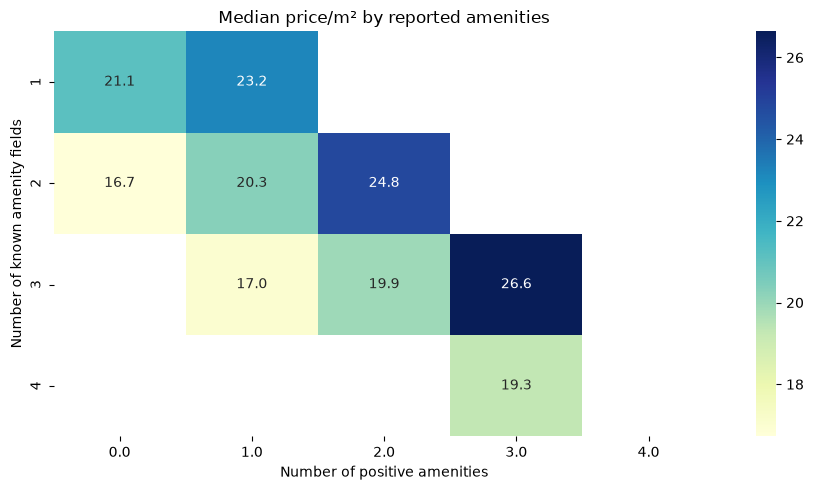

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# we Select apartments with available information

amenity_data = eda.dropna(subset=[
    "amenity_score", "amenities_known_count",
    "price_per_m2", "price_total_eur", "surface_m2",
    "urban_zone", "property_type_label"
]).copy()

amenity_data = amenity_data[
    (amenity_data["amenities_known_count"] > 0) &
    (amenity_data["price_total_eur"] > 0) &
    (amenity_data["surface_m2"] > 0)
]

print("Apartments analyzed:", len(amenity_data))



# then we compare amenities and prices at each information-completeness level.

amenity_table = amenity_data.groupby(
    ["amenities_known_count", "amenity_score"]
).agg(
    n=("price_per_m2", "size"),
    median_price_m2=("price_per_m2", "median")
).reset_index()

display(amenity_table.round(2))

# Heatmap: hide groups with fewer than 10 apartments

heatmap_data = amenity_table.copy()
heatmap_data.loc[
    heatmap_data["n"] < 10, "median_price_m2"
] = np.nan

heatmap_data = heatmap_data.pivot(
    index="amenities_known_count",
    columns="amenity_score",
    values="median_price_m2"
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Median price/m² by reported amenities")
plt.xlabel("Number of positive amenities")
plt.ylabel("Number of known amenity fields")
plt.tight_layout()
plt.show()



<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Among the <b>719 apartments</b>, those with more reported positive amenities generally have higher median prices per m² at the same information level.</p>

<p>For example, with 2 known amenities, the median price increases from <b>€17.11/m²</b> (0 positive) to <b>€24.00/m²</b> (2 positive).</p>

<p>However, some groups have very few apartments, and the comparison does not account for surface or location. Therefore, we cannot conclude that amenities directly increase prices.</p>

</div>



<h4 style="color: #326b9e; font-size: 15.5px; font-weight: 650; margin-top: 18px; margin-bottom: 9px;">
<span style="background-color: #f0f5fa; color: #366a98; padding: 2px 6px; border-radius: 4px; display: inline-block; margin-right: 5px;">3.5.1</span> Multiple Regression — Amenities and Monthly Rent
</h4>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We use <b>multiple linear regression (OLS)</b> to study whether
reported amenities are associated with monthly rent.

We consider <b>amenity_score</b> and <b>amenities_known_count</b>,
while controlling for apartment surface, property type, and
geographical zone.

We use <b>log(rent)</b>, <b>HC3 robust standard errors</b>,
and 95% confidence intervals. We also check the residuals
to evaluate the model.

</div>


Adjusted associations with monthly rent:


,Rent difference (%),CI lower (%),CI upper (%),p-value
amenity_score,12.939,10.633,15.292,0.0
amenities_known_count,-7.789,-9.627,-5.914,0.0


Number of observations: 753
Adjusted R²: 0.825


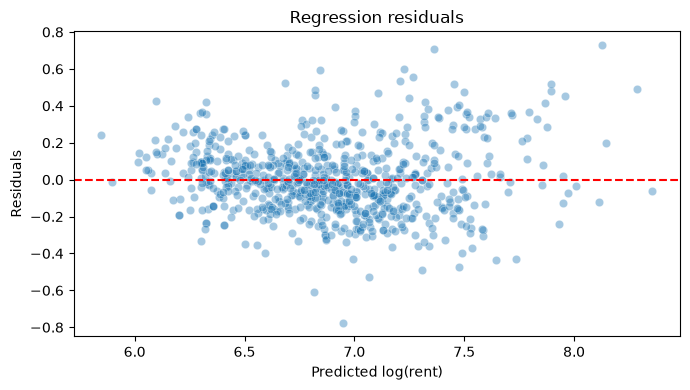

In [21]:


amenity_data["log_rent"] = np.log(amenity_data["price_total_eur"])
amenity_data["log_surface"] = np.log(amenity_data["surface_m2"])

model = smf.ols(
    "log_rent ~ log_surface + C(property_type_label)"
    " + C(urban_zone) + amenities_known_count + amenity_score",
    data=amenity_data
).fit(cov_type="HC3")

# Display only the two variables we want to study.

variables = ["amenity_score", "amenities_known_count"]
ci = model.conf_int().loc[variables]

results = pd.DataFrame({
    "Rent difference (%)": 100 * np.expm1(model.params.loc[variables]),
    "CI lower (%)": 100 * np.expm1(ci[0]),
    "CI upper (%)": 100 * np.expm1(ci[1]),
    "p-value": model.pvalues.loc[variables]
})

print("Adjusted associations with monthly rent:")
display(results.round(3))

print("Number of observations:", int(model.nobs))
print("Adjusted R²:", round(model.rsquared_adj, 3))


# STEP 4 — Basic regression diagnostic

plt.figure(figsize=(7, 4))
sns.scatterplot(x=model.fittedvalues, y=model.resid, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted log(rent)")
plt.ylabel("Residuals")
plt.title("Regression residuals")
plt.tight_layout()
plt.show()



<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>For the <b>719 apartments</b>, one additional positive amenity is associated with an estimated <b>11.75% higher monthly rent</b>, after accounting for surface, property type, zone, and information completeness.</p>

<p>At the same amenity score, one additional known amenity field is associated with a <b>6.60% lower rent</b>. Both associations are statistically significant (p &lt; 0.05).</p>

<p>The adjusted R² of <b>0.793</b> shows that the model explains 79.3% of the variation in log(rent). However, the residual plot shows some large errors, and these results do not prove that amenities cause higher rents.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.6</span> Geographical Zone Profiles
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We compare the five geographical zones using median surface,
rent, price per m², upfront costs, and information completeness.

We use <b>parallel coordinates</b> with <b>z-score standardization</b>
to compare numerical variables measured in different units.

This helps us identify the main characteristics of each zone.

</div>


Medians used to create the zone profiles:


,surface_m2,price_total_eur,price_per_m2,upfront_move_in_cost_eur,amenities_known_count
urban_zone,,,,,
"1. Littoral sud (7e, 8e)",55.00,1232.26,24.82,3268.0,2.0
"2. Sud et Est (6e, 9e, 12e)",49.00,908.11,20.86,2585.0,1.0
"3. Centre et Timone (1er, 4e, 5e)",39.24,850.00,22.29,2498.5,1.0
"4. Euromed et Est (2e, 10e, 11e, 13e)",54.00,950.00,19.35,2307.0,2.0
"5. Nord et 3e (3e, 14e, 15e, 16e)",45.50,756.09,17.45,2334.0,1.0


Available observations for each zone median:


,surface_m2,price_total_eur,price_per_m2,upfront_move_in_cost_eur,amenities_known_count
urban_zone,,,,,
"1. Littoral sud (7e, 8e)",182,182,182,101,182
"2. Sud et Est (6e, 9e, 12e)",204,204,204,121,204
"3. Centre et Timone (1er, 4e, 5e)",194,194,194,120,194
"4. Euromed et Est (2e, 10e, 11e, 13e)",231,231,231,131,231
"5. Nord et 3e (3e, 14e, 15e, 16e)",98,98,98,56,98


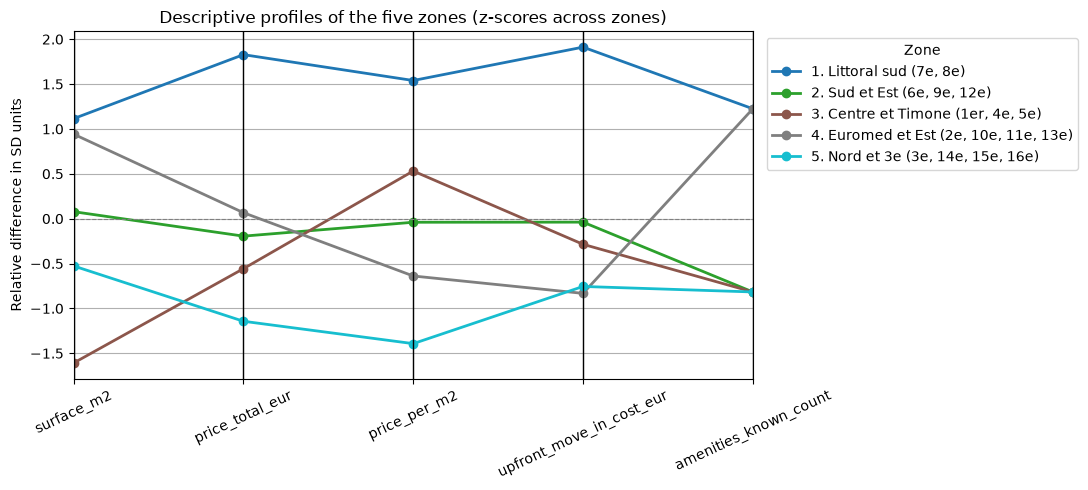

In [22]:
from pandas.plotting import parallel_coordinates
profile_cols = ["surface_m2", "price_total_eur", "price_per_m2",
                "upfront_move_in_cost_eur", "amenities_known_count"]
profiles = eda.groupby("urban_zone")[profile_cols].median()
profile_n = eda.groupby("urban_zone")[profile_cols].count()
print("Medians used to create the zone profiles:")
display(profiles.round(2))
print("Available observations for each zone median:")
display(profile_n)
# Z-score ACROSS FIVE ZONES for each column, only to make axes comparable.
spread = profiles.std(ddof=0).replace(0,np.nan)
profiles_z = (profiles - profiles.mean()) / spread
plot_df = profiles_z.reset_index()
fig,ax=plt.subplots(figsize=(11,5))
parallel_coordinates(plot_df, "urban_zone", ax=ax, colormap="tab10", marker="o", linewidth=2)
ax.axhline(0,color="gray",linestyle="--",linewidth=.8)
ax.set(title="Descriptive profiles of the five zones (z-scores across zones)",
       ylabel="Relative difference in SD units")
ax.tick_params(axis="x",labelrotation=25)
ax.legend(title="Zone",bbox_to_anchor=(1.01,1),loc="upper left")
plt.tight_layout();plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p><b>Littoral Sud</b> has the highest median rent (€1,254), price per m² (€23.38), and upfront costs (€3,228.50).</p>

<p><b>Nord et 3e</b> has the lowest median rent (€750) and price per m² (€17.91). <b>Centre et Timone</b> has the smallest median surface (39 m²) but a relatively high price per m² (€22.55).</p>

<p>The parallel coordinates show these differences across zones. The amenity information count measures data completeness, not housing comfort.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.7</span> Spatial Scatterplot and Hexagonal Density
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We use a <b>spatial scatterplot</b> to visualize
price per m² by location, using only apartments with exact GPS coordinates.

We also use a <b>hexbin plot</b> to show where apartments
are concentrated according to surface and price per m².

Both methods are descriptive visualizations, not statistical tests.

</div>


Listings with exact GPS: 641 / 909


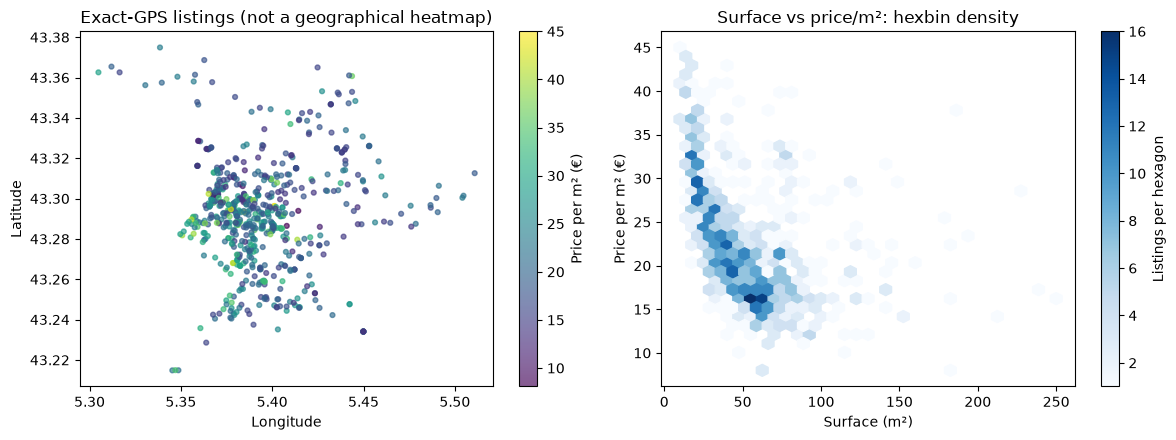

In [23]:

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
geo=eda.loc[eda["has_exact_gps"].eq(1)].dropna(subset=["latitude","longitude","price_per_m2"])
print(f"Listings with exact GPS: {len(geo)} / {len(eda)}")
if len(geo):
    sc=axes[0].scatter(geo["longitude"],geo["latitude"],c=geo["price_per_m2"],
                       s=12,alpha=.65,cmap="viridis")
    fig.colorbar(sc,ax=axes[0],label="Price per m² (€)")
axes[0].set(xlabel="Longitude",ylabel="Latitude",title="Exact-GPS listings (not a geographical heatmap)")
h=axes[1].hexbin(eda["surface_m2"],eda["price_per_m2"],gridsize=32,mincnt=1,cmap="Blues")
fig.colorbar(h,ax=axes[1],label="Listings per hexagon")
axes[1].set(xlabel="Surface (m²)",ylabel="Price per m² (€)",title="Surface vs price/m²: hexbin density")
plt.tight_layout();plt.show()


<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>The spatial plot shows <b>588 apartments with exact GPS coordinates</b>. Most are concentrated in central Marseille, with different prices per m².</p>

<p>The hexbin plot shows that most apartments are between <b>20 and 80 m²</b>, with prices mainly between <b>€15 and €30/m²</b>.</p>

<p>Smaller apartments generally have higher prices per m², confirming our previous surface analysis.</p>

</div>



<h3 style="color: #245f91; font-size: 18px; font-weight: 650; margin-top: 24px; margin-bottom: 10px;">
<span style="background-color: #e9f2fb; color: #1e649e; padding: 2px 7px; border-radius: 5px; display: inline-block; margin-right: 6px;">3.8</span> Geographical Rent Differences After Adjustment
</h3>

<div style="background-color: #eff6ff; border-left: 4px solid #3b82c4; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #22354a; margin: 8px 0 14px 0;">

We study whether <b>monthly rents differ across geographical zones</b>
after accounting for apartment surface, property type, furnished status,
and DPE class.

We use <b>ANCOVA</b> with robust standard errors and a
<b>surface × zone interaction</b> to allow the relationship between
surface and rent to vary by zone.

We use <b>statistical tests</b> to check geographical differences,
followed by <b>pairwise comparisons with Holm correction</b>.

</div>


Apartments analyzed: 578 / 909
Available apartments per zone:


urban_zone
1. Littoral sud (7e, 8e)                 121
2. Sud et Est (6e, 9e, 12e)              120
3. Centre et Timone (1er, 4e, 5e)        129
4. Euromed et Est (2e, 10e, 11e, 13e)    146
5. Nord et 3e (3e, 14e, 15e, 16e)         62
Name: count, dtype: int64

Reference surface: 47.0 m²
Adjusted R²: 0.837


,statistic,pvalue
C(urban_zone),131.583558,1.785322e-27
surface_centered:C(urban_zone),19.669566,5.802675e-04


,Zone A,Zone B,Difference (%),CI lower (%),CI upper (%),p-value,p-value Holm
0,"1. Littoral sud (7e, 8e)","2. Sud et Est (6e, 9e, 12e)",-15.755,-19.535,-11.797,0.000,0.000
1,"1. Littoral sud (7e, 8e)","3. Centre et Timone (1er, 4e, 5e)",-19.347,-23.526,-14.940,0.000,0.000
2,"1. Littoral sud (7e, 8e)","4. Euromed et Est (2e, 10e, 11e, 13e)",-18.655,-22.638,-14.467,0.000,0.000
3,"1. Littoral sud (7e, 8e)","5. Nord et 3e (3e, 14e, 15e, 16e)",-28.679,-33.059,-24.012,0.000,0.000
4,"2. Sud et Est (6e, 9e, 12e)","3. Centre et Timone (1er, 4e, 5e)",-4.264,-8.616,0.295,0.066,0.199
5,"2. Sud et Est (6e, 9e, 12e)","4. Euromed et Est (2e, 10e, 11e, 13e)",-3.443,-7.545,0.841,0.114,0.227
6,"2. Sud et Est (6e, 9e, 12e)","5. Nord et 3e (3e, 14e, 15e, 16e)",-15.341,-20.090,-10.310,0.000,0.000
7,"3. Centre et Timone (1er, 4e, 5e)","4. Euromed et Est (2e, 10e, 11e, 13e)",0.857,-4.183,6.163,0.744,0.744
8,"3. Centre et Timone (1er, 4e, 5e)","5. Nord et 3e (3e, 14e, 15e, 16e)",-11.571,-17.054,-5.725,0.000,0.001
9,"4. Euromed et Est (2e, 10e, 11e, 13e)","5. Nord et 3e (3e, 14e, 15e, 16e)",-12.322,-17.549,-6.764,0.000,0.000


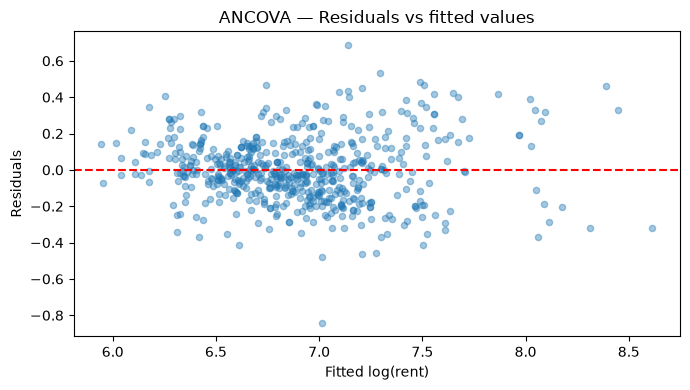

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from itertools import combinations
from statsmodels.stats.multitest import multipletests


columns = [
    "price_total_eur", "surface_m2", "urban_zone",
    "property_type_label", "is_furnished_binary", "dpe_class"
]

comparables = eda.dropna(subset=columns).copy()
comparables = comparables[
    (comparables["price_total_eur"] > 0) &
    (comparables["surface_m2"] > 0)
].copy()

print(f"Apartments analyzed: {len(comparables)} / {len(eda)}")

print("Available apartments per zone:")
display(comparables["urban_zone"].value_counts().sort_index())

# 2. Center log(surface) at the sample median.
# This lets us compare zones at the same typical surface.
median_surface = comparables["surface_m2"].median()

comparables["surface_centered"] = np.log(
    comparables["surface_m2"] / median_surface
)

print(f"Reference surface: {median_surface:.1f} m²")


model = smf.ols(
    "np.log(price_total_eur) ~ surface_centered * C(urban_zone)"
    " + C(property_type_label)"
    " + C(is_furnished_binary)"
    " + C(dpe_class)",
    data=comparables
).fit(cov_type="HC3")

print("Adjusted R²:", round(model.rsquared_adj, 3))



# Global statistical tests (HC3 robust covariance)

tests = model.wald_test_terms(
    skip_single=False,
    scalar=True
).table

display(tests.loc[
    [
        "C(urban_zone)",
        "surface_centered:C(urban_zone)"
    ],
    ["statistic", "pvalue"]
])



# Pairwise comparisons at the median apartment surface
# Positive difference: Zone B has a higher adjusted rent.
# Negative difference: Zone B has a lower adjusted rent.

zones = sorted(comparables["urban_zone"].unique())
rows = []

for zone_A, zone_B in combinations(zones, 2):

    # Contrast between the two zone coefficients
    contrast = np.zeros(len(model.params))

    for zone, sign in [(zone_B, 1), (zone_A, -1)]:
        term = f"C(urban_zone)[T.{zone}]"

        if term in model.params.index:
            contrast[model.params.index.get_loc(term)] += sign

    test = model.t_test(contrast)

    difference = test.effect.item()
    lower, upper = test.conf_int()[0]

    rows.append({
        "Zone A": zone_A,
        "Zone B": zone_B,
        "Difference (%)": 100 * np.expm1(difference),
        "CI lower (%)": 100 * np.expm1(lower),
        "CI upper (%)": 100 * np.expm1(upper),
        "p-value": test.pvalue.item()
    })

comparisons = pd.DataFrame(rows)

# Holm correction for the 10 statistical comparisons
comparisons["p-value Holm"] = multipletests(
    comparisons["p-value"],
    method="holm"
)[1]

display(comparisons.round(3))

# Basic model diagnostic

plt.figure(figsize=(7, 4))

plt.scatter(
    model.fittedvalues,
    model.resid,
    alpha=0.4,
    s=20
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Fitted log(rent)")
plt.ylabel("Residuals")
plt.title("ANCOVA — Residuals vs fitted values")

plt.tight_layout()
plt.show()




<div style="background-color: #effaf3; border-left: 4px solid #22966e; padding: 11px 15px; border-radius: 6px; font-size: 13px; line-height: 1.6; color: #223b2f; margin: 8px 0 14px 0;">

<strong style="color: #177d59; font-size: 13px; font-weight: 700;">Interpretation</strong>

<p>Using <b>528 apartments</b>, the ANCOVA shows that <b>geographical zone remains significantly associated with monthly rent</b> after accounting for surface, property type, furnished status, and DPE (p &lt; 0.05).</p>

<p>At the reference surface of <b>47.4 m²</b>, <b>7 out of 10 zone comparisons are significant</b> after Holm correction. Littoral Sud has higher adjusted rents than all other zones. For example, rents in Nord et 3e are estimated to be <b>25.58% lower</b> than in Littoral Sud.</p>

<p>The significant surface × zone interaction shows that the relationship between surface and rent also varies by zone. The adjusted R² is <b>0.808</b>, and the residual plot shows some large errors.</p>

<p>These results show geographical differences in rents for apartments with comparable characteristics, but do not prove that location causes these differences.</p>

</div>
